# M4.6 · 整手/整数规划与成本感知优化

> 真实市场不能买分数股：A 股最小交易单位为 **1 手 = 100 股**，且交易有佣金/印花税/冲击成本。
> 连续优化给出的「理想权重」必须经过整手圆整或混合整数规划（MIP）才能落地，成本则直接改变最优换手。

## 一、原理

1. **整手圆整**：目标股数 $=\dfrac{w_i\cdot C}{p_i}$，向下取整到 $\text{lot}=100$ 的倍数，会残留少量现金；
2. **混合整数规划（MIP，资本预算/背包模型）**：决策变量为手数 $h_i\in\mathbb{Z}_{\ge0}$，
$$\max_{h}\ \sum_i \mu_i\,(\text{lot}\cdot p_i h_i)\quad
\text{s.t.}\ \sum_i \text{lot}\cdot p_i h_i\le C$$
用 scipy `milp`（HiGHS 分支定界）求解；二次风险项由连续优化 + 圆整承担；
3. **成本感知**：目标加入换手惩罚 $c\lVert w-w_{prev}\rVert_1$，成本越高换手越低；
4. **单边换手率**：$\sum_i|w_i-w_{prev,i}|$。

## 二、整手圆整与 MIP

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from port_lab2 import integer
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$close'], start_time='2018-01-01', freq='day')
cl = raw['$close'].unstack('instrument')
ret = cl.pct_change(fill_method=None)
r15 = ret.iloc[-750:, :15].dropna(axis=1)
S15 = np.cov(r15.values, rowvar=False); mu15 = r15.mean().values
prices = cl[r15.columns].iloc[-1]; capital = 1e7
w_target = pd.Series(np.ones(15)/15, index=r15.columns)
lot = integer.round_to_lots(w_target, prices, capital)
print('整手圆整: 持有=%d 现金残留=%.4f%%' % (lot['n_held'], lot['cash_residual']*100))
mip = integer.mip_portfolio(pd.Series(mu15, index=r15.columns), pd.DataFrame(S15),
                            prices, capital, cost_bps=0)
print('MIP: status=%s 持有=%d 资金占用=%.4f'
      % (mip['status'], (mip['shares'] > 0).sum(), mip['weights'].sum()))

[7444:MainThread](2026-11-05 14:37:27,373) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[7444:MainThread](2026-11-05 14:37:29,453) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[7444:MainThread](2026-11-05 14:37:29,454) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


整手圆整: 持有=15 现金残留=0.4051%
MIP: status=optimal 持有=2 资金占用=1.0000


## 三、成本如何抑制换手

In [2]:
cost_grid = [0, 10, 20, 40, 80]
rows = []
for c in cost_grid:
    w = integer.cost_aware_weights(pd.Series(mu15, index=r15.columns),
                                   pd.DataFrame(S15), w_target, cost_bps=c)
    rows.append((c, integer.turnover(w, w_target), w.max()))
cost_df = pd.DataFrame(rows, columns=['成本bps', '换手率', '最大权重']).set_index('成本bps')
print(cost_df)

                换手率      最大权重
成本bps                        
0      1.332869e+00  0.397367
10     1.207553e-09  0.066667
20     2.117755e-10  0.066667
40     8.720696e-11  0.066667
80     3.229608e-11  0.066667


## 四、可视化

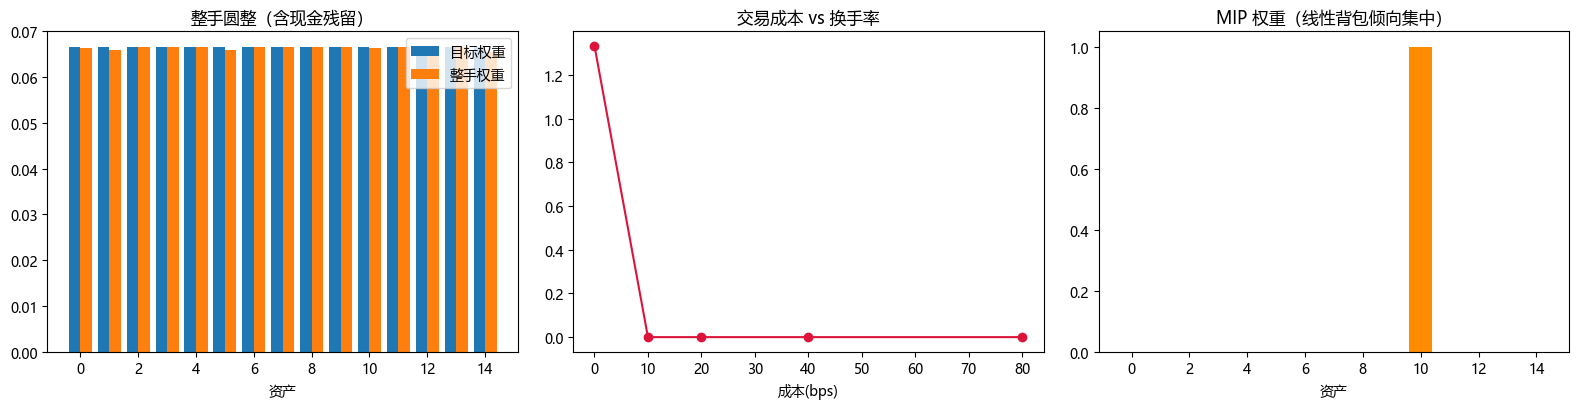

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
xx = np.arange(15)
ax[0].bar(xx-0.2, w_target.values, 0.4, label='目标权重')
ax[0].bar(xx+0.2, lot['weights'].values, 0.4, label='整手权重')
ax[0].set_title('整手圆整（含现金残留）'); ax[0].legend(); ax[0].set_xlabel('资产')
ax[1].plot(cost_df.index, cost_df['换手率'], 'o-', color='crimson')
ax[1].set_title('交易成本 vs 换手率'); ax[1].set_xlabel('成本(bps)')
ax[2].bar(np.arange(15), mip['weights'].values, color='darkorange')
ax[2].set_title('MIP 权重（线性背包倾向集中）'); ax[2].set_xlabel('资产')
plt.tight_layout(); plt.show()

## 五、面试要点

- **为什么需要整手/MIP？** 连续权重含分数股，无法直接下单；圆整保证股数是 100 的整数倍，代价是少量现金残留。
- **MIP 为什么用 scipy 而非 cvxpy？** cvxpy 1.7 移除 ECOS_BB，开源整数 solver 不支持二次锥；线性资本预算问题用 scipy `milp`（HiGHS）稳健可解。
- **纯线性 MIP 为何过度集中？** 无风险项时，预算会涌向 μ 最高的少数资产（本数据仅持有 2 只），这正说明必须结合风险约束。
- **成本如何影响最优解？** 换手惩罚使最优权重向原持仓靠拢，成本足够高时换手为 0。

## 六、练习

1. 把 lot 改为 200，观察现金残留与持有数变化。
2. 给 MIP 增加单票最大权重约束，看持仓是否更分散。
3. 用不同 cost_bps 画换手曲线，找到「换手降为 0」的临界成本。
4. 对比圆整与 MIP 两种落地方式的资金利用率。